In [1]:
import os, warnings
from pathlib import Path
while not Path("pyproject.toml").exists() and Path.cwd() != Path.cwd().parent:
    os.chdir(Path.cwd().parent)  # run from the project root so data/ paths resolve (the notebook sits in studies/<name>/notebooks)
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from cifresignificative.studies.italy_productivity.analysis.data import *
from cifresignificative.core.viz.style import *
apply_style()
panel = load_panel()


# 03 - Debt, interest and investment
Is Italy's debt a story of deficits, or of interest and growth?

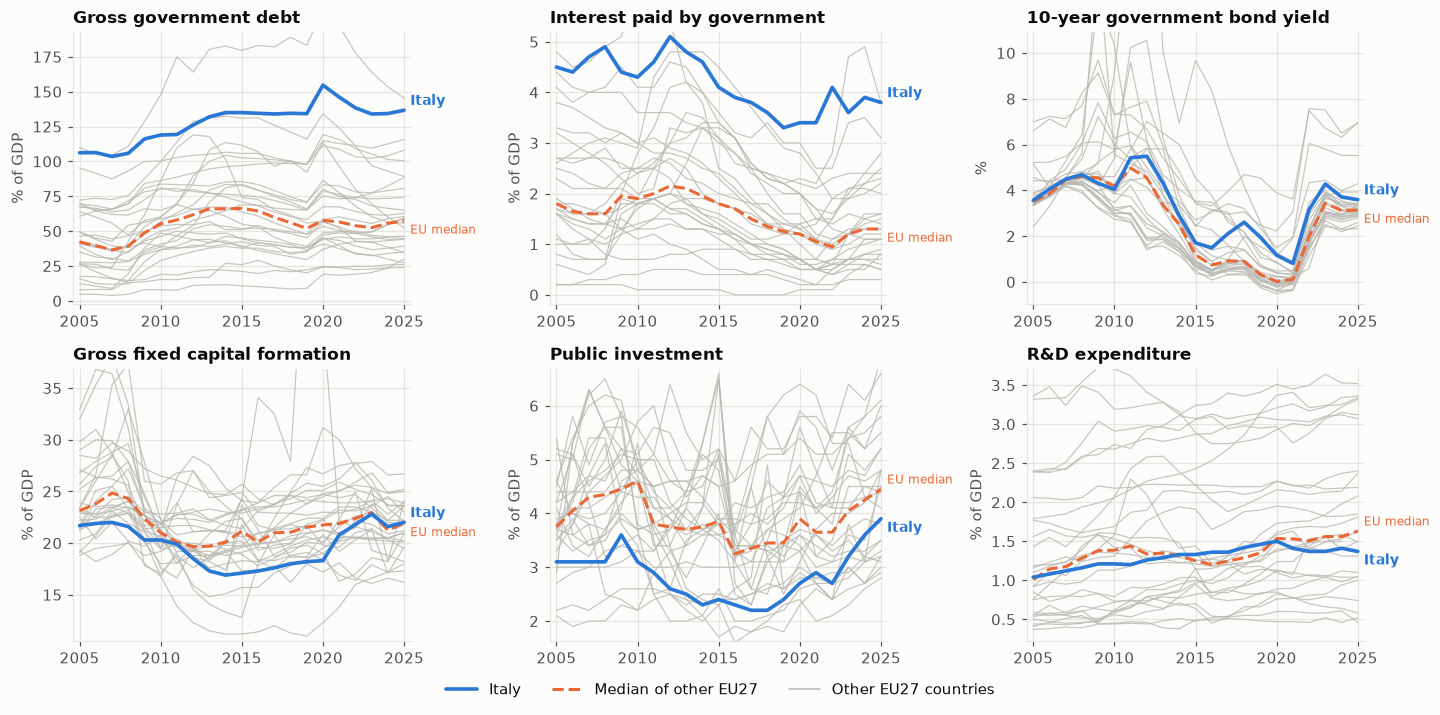

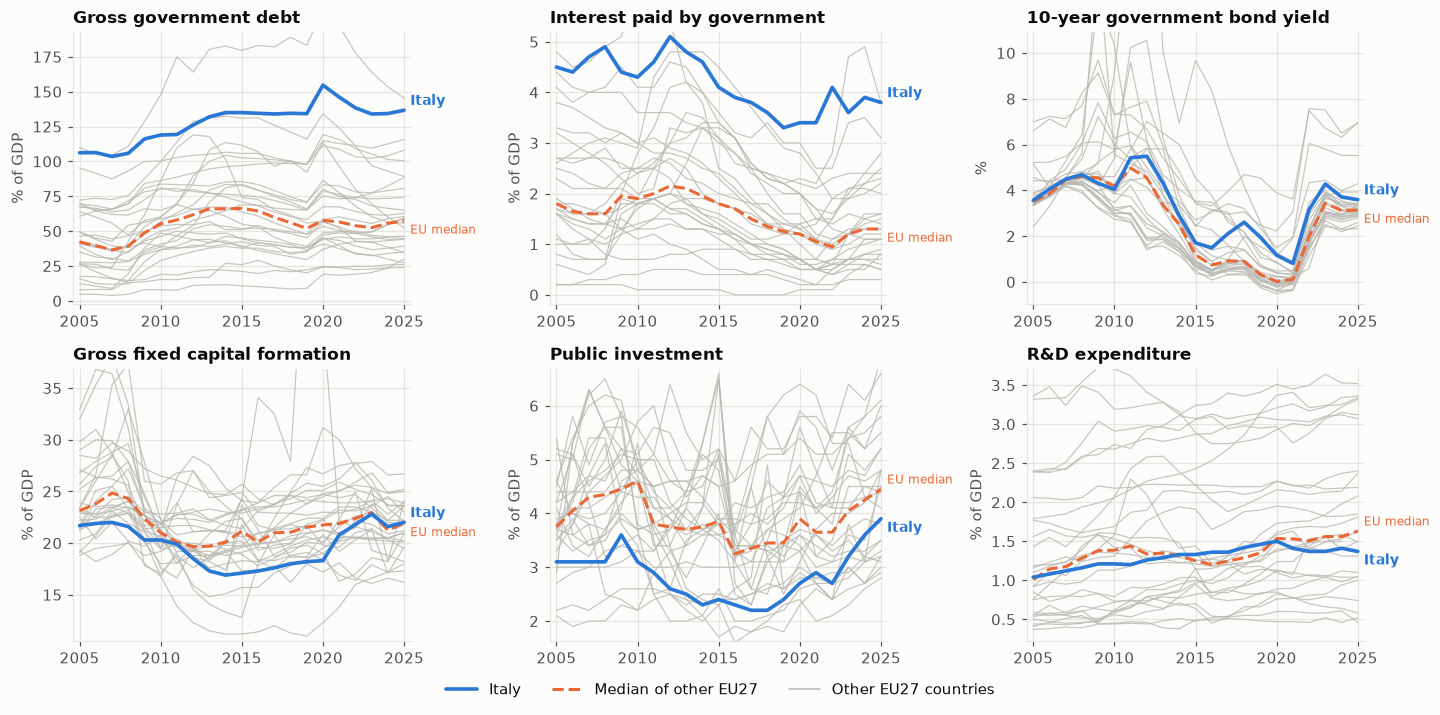

In [2]:
small_multiples(panel, [
    ("gov_debt_pct_gdp", "Gross government debt", "% of GDP"),
    ("gov_interest_pct_gdp", "Interest paid by government", "% of GDP"),
    ("long_term_yield", "10-year government bond yield", "%"),
    ("gfcf_pct_gdp", "Gross fixed capital formation", "% of GDP"),
    ("gov_pubinv_pct_gdp", "Public investment", "% of GDP"),
    ("rd_pct_gdp", "R&D expenditure", "% of GDP"),
], ncols=3, name="03_debt_investment_overview")

Average primary balance 2005-2024 (% GDP): {'ITA': 0.12, 'DEU': 0.62, 'FRA': -2.56, 'ESP': -2.68, 'PRT': -0.78, 'GRC': -1.71} | median of other EU27: -0.87


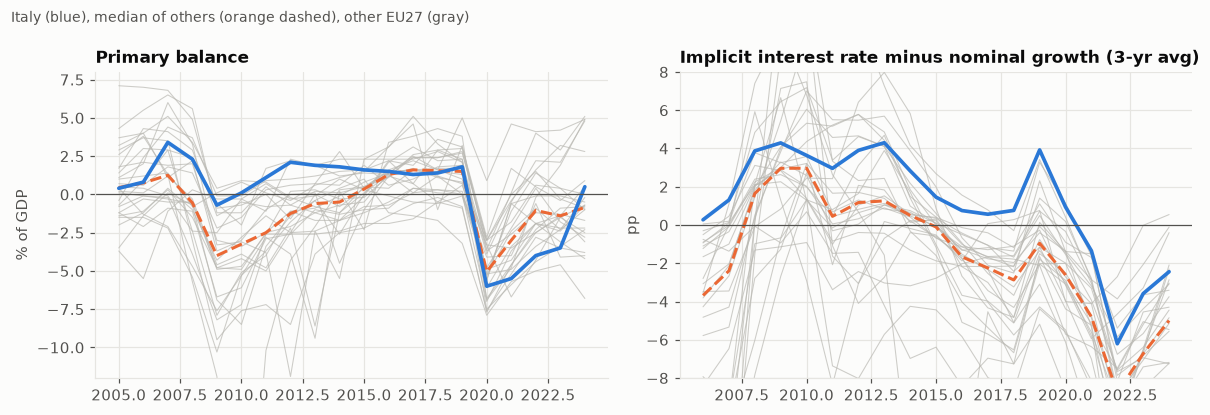

In [3]:
# Primary balance (balance + interest) and the interest-growth differential
bal = wide(panel, "gov_balance_pct_gdp"); intr = wide(panel, "gov_interest_pct_gdp")
pb = (bal + intr).loc[2005:2024]
print("Average primary balance 2005-2024 (% GDP):", pb.mean()[[ITALY, "DEU", "FRA", "ESP", "PRT", "GRC"]].round(2).to_dict(),
      "| median of other EU27:", round(pb.mean().drop(["ITA", "GBR", "USA", "JPN", "EU27"], errors="ignore").median(), 2))
rg = (implicit_interest_rate(panel) - nominal_growth(panel)).loc[2006:2024]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
w = pb; med = eu_median_ex_italy(w)
for c in EU27_ISO3:
    if c != ITALY: axes[0].plot(w.index, w[c], color=PEER_C, lw=0.7, alpha=0.7)
axes[0].plot(med.index, med, color=EU_C, lw=2, ls="--"); axes[0].plot(w.index, w[ITALY], color=ITALY_C, lw=2.4); axes[0].axhline(0, color=INK2, lw=0.8)
axes[0].set_title("Primary balance"); axes[0].set_ylabel("% of GDP"); axes[0].set_ylim(-12, 8)
rgm = rg.rolling(3, center=True, min_periods=1).mean()
for c in EU27_ISO3:
    if c != ITALY: axes[1].plot(rgm.index, rgm[c], color=PEER_C, lw=0.7, alpha=0.7)
axes[1].plot(rgm.index, rgm.drop(columns=[ITALY]).median(axis=1), color=EU_C, lw=2, ls="--"); axes[1].plot(rgm.index, rgm[ITALY], color=ITALY_C, lw=2.4); axes[1].axhline(0, color=INK2, lw=0.8)
axes[1].set_title("Implicit interest rate minus nominal growth (3-yr avg)"); axes[1].set_ylabel("pp"); axes[1].set_ylim(-8, 8)
fig.suptitle("Italy (blue), median of others (orange dashed), other EU27 (gray)", fontsize=9, color=INK2, x=0.01, ha="left"); fig.tight_layout(); save(fig, "03_primary_balance_rg")

,2005-2014,2014-2024
ITA,28.8,-0.7
DEU,7.3,-13.0
FRA,28.0,16.4
ESP,62.0,-3.0
PRT,60.3,-39.5
GRC,72.8,-29.2


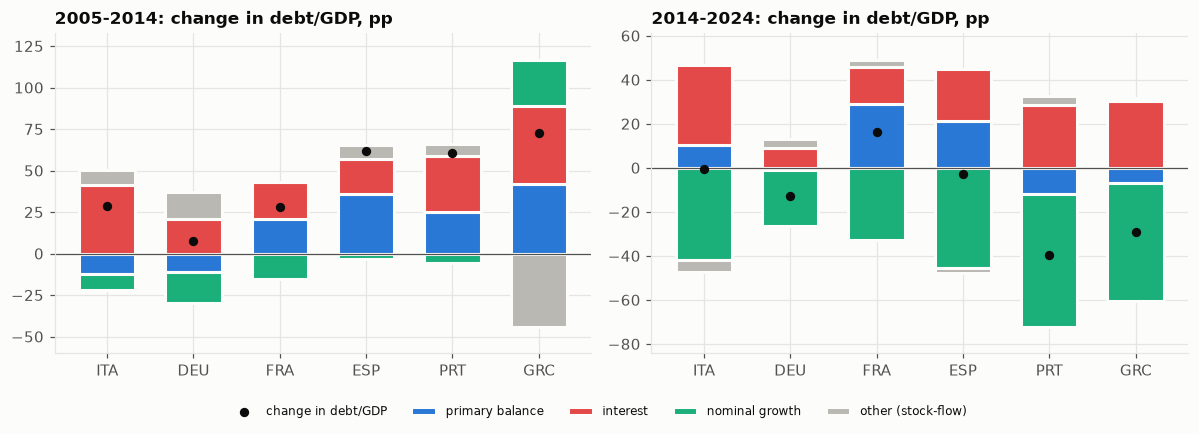

In [4]:
# What moved debt/GDP? Contributions in pp of GDP, two sub-periods
countries = ["ITA", "DEU", "FRA", "ESP", "PRT", "GRC"]
periods = [(2005, 2014), (2014, 2024)]
parts = ["primary balance", "interest", "nominal growth", "other (stock-flow)"]
cols = ["#2a78d6", "#e34948", "#1baf7a", "#b9b8b2"]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharex=True)
for ax, (a, b) in zip(axes, periods):
    dec = pd.DataFrame({c: debt_decomposition(panel, c, a, b) for c in countries}).T
    pos = np.zeros(len(dec)); neg = np.zeros(len(dec))
    for part, col in zip(parts, cols):
        v = dec[part].values; base = np.where(v >= 0, pos, neg)
        ax.bar(range(len(dec)), v, bottom=base, color=col, label=part, edgecolor=SURFACE, linewidth=2, width=0.65)
        pos += np.where(v >= 0, v, 0); neg += np.where(v < 0, v, 0)
    ax.scatter(range(len(dec)), dec.sum(axis=1), color=INK, zorder=5, s=26, label="change in debt/GDP")
    ax.axhline(0, color=INK2, lw=0.8); ax.set_xticks(range(len(dec)), dec.index); ax.set_title(f"{a}-{b}: change in debt/GDP, pp"); ax.margins(y=0.1)
h, l = axes[0].get_legend_handles_labels(); fig.legend(h, l, loc="lower center", ncol=5, fontsize=8, bbox_to_anchor=(0.5, -0.04)); fig.tight_layout(rect=(0, 0.04, 1, 1)); save(fig, "03_debt_decomposition")
display(pd.DataFrame({f"{a}-{b}": {c: round(debt_decomposition(panel, c, a, b).sum(), 1) for c in countries} for a, b in periods}))

Peak spread: 2012 3.99 | 2024: 1.39


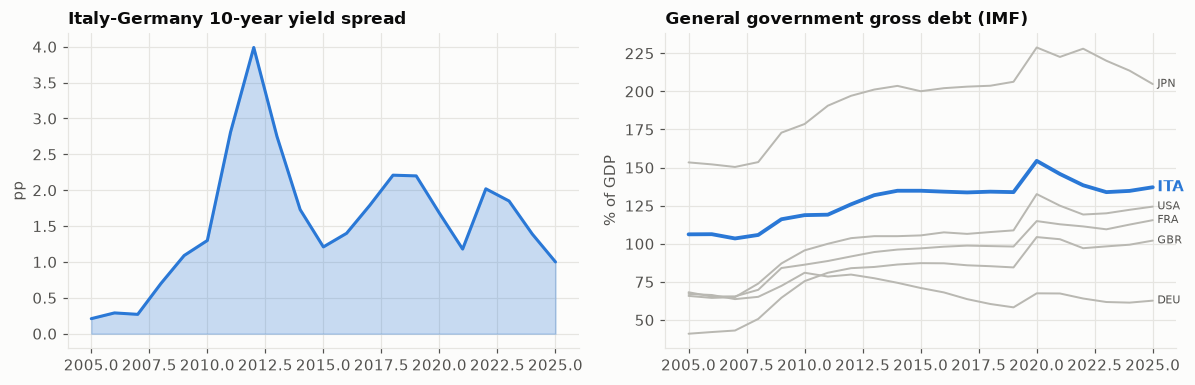

In [5]:
# Spread of Italian vs German 10-year yields, and debt of the US and Japan for scale (IMF, general government)
y = wide(panel, "long_term_yield")
spread = (y[ITALY] - y["DEU"]).dropna()
imfd = wide(panel, "imf_gov_debt_pct_gdp", [ITALY, "DEU", "FRA", "ESP", "USA", "JPN", "GBR"])
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].fill_between(spread.index, spread, color=ITALY_C, alpha=0.25); axes[0].plot(spread.index, spread, color=ITALY_C, lw=2); axes[0].set_title("Italy-Germany 10-year yield spread"); axes[0].set_ylabel("pp")
for c, col, ls in [("USA", PEER_C, "-"), ("JPN", PEER_C, "-"), ("GBR", PEER_C, "-"), ("DEU", PEER_C, "-"), ("FRA", PEER_C, "-")]:
    axes[1].plot(imfd.index, imfd[c], color=col, lw=1.3); axes[1].annotate(c, (imfd.index[-1], imfd[c].iloc[-1]), xytext=(3, 0), textcoords="offset points", fontsize=7, color=INK2, va="center")
axes[1].plot(imfd.index, imfd[ITALY], color=ITALY_C, lw=2.5); axes[1].annotate("ITA", (imfd.index[-1], imfd[ITALY].iloc[-1]), xytext=(3, 0), textcoords="offset points", color=ITALY_C, fontweight="bold", va="center")
axes[1].set_title("General government gross debt (IMF)"); axes[1].set_ylabel("% of GDP"); fig.tight_layout(); save(fig, "03_spread_benchmarks")
print("Peak spread:", spread.idxmax(), round(spread.max(), 2), "| 2024:", round(spread.loc[2024], 2))

In [6]:
# Figures quoted in the takeaways: Italy, median of the other members, rank (1 = highest) among the members with a value
def quoted(ind, years, countries=()):
    w = wide(panel, ind, EU27_ISO3)
    for y in years:
        r = w.loc[y].dropna()
        print(f"{ind} {y}: Italy {r[ITALY]:.2f} | median of the others {r.drop(ITALY).median():.2f} | rank {int(r.rank(ascending=False)[ITALY])}/{len(r)}" + "".join(f" | {c} {r[c]:.2f}" for c in countries))  # two decimals: a takeaway rounded to one is then checked without ties
quoted("gov_interest_pct_gdp", [2024]); quoted("gov_pubinv_pct_gdp", [2024]); quoted("gfcf_pct_gdp", [2014, 2024]); quoted("gov_debt_pct_gdp", [2005, 2020, 2024])
w = wide(panel, "gov_pubinv_pct_gdp", EU27_ISO3).loc[2012:2019]; m = w.drop(columns=ITALY).median(axis=1)
print(f"public investment 2012-2019: Italy {w[ITALY].min():.2f}-{w[ITALY].max():.2f} | median of the others {m.min():.2f}-{m.max():.2f}")
for a, b in ((2005, 2014), (2014, 2024)):
    print(f"debt/GDP contributions {a}-{b}, pp:", {k: round(float(v)) for k, v in debt_decomposition(panel, ITALY, a, b).items()})

gov_interest_pct_gdp 2024: Italy 3.90 | median of the others 1.30 | rank 2/27
gov_pubinv_pct_gdp 2024: Italy 3.60 | median of the others 4.25 | rank 16/27
gfcf_pct_gdp 2014: Italy 16.90 | median of the others 20.10 | rank 23/27
gfcf_pct_gdp 2024: Italy 21.60 | median of the others 21.25 | rank 13/27
gov_debt_pct_gdp 2005: Italy 106.20 | median of the others 42.25 | rank 2/27
gov_debt_pct_gdp 2020: Italy 154.70 | median of the others 57.70 | rank 2/27
gov_debt_pct_gdp 2024: Italy 134.30 | median of the others 55.65 | rank 2/27
public investment 2012-2019: Italy 2.20-2.60 | median of the others 3.25-3.85
debt/GDP contributions 2005-2014, pp: {'primary balance': -13, 'interest': 41, 'nominal growth': -9, 'other (stock-flow)': 9}
debt/GDP contributions 2014-2024, pp: {'primary balance': 10, 'interest': 36, 'nominal growth': -42, 'other (stock-flow)': -5}


## Takeaways (Eurostat general-government data; IMF for US/JP)
- Debt was 106% of GDP in 2005 and 134% in 2024 (155% at the 2020 peak): the second highest in the EU27 in 2024, with interest at 3.9% of GDP against a 1.3% median.
- **It is not a primary-deficit story.** Italy's average primary balance over 2005-2024 was +0.1% of GDP, versus -0.9% for the median, +0.6% Germany, -2.6% France, -2.7% Spain.
- **It is an interest-and-growth story.** In 2005-2014 debt rose 28.8 pp: interest added +41 pp, offset by primary surpluses (-13) and nominal growth (-9). In 2014-2024 debt was nearly flat (-0.7 pp): interest still added +36 pp, but nominal growth (-42) paid it back, and primary balances turned to deficits (+11 pp).
- The Italy-Germany 10-year spread peaked at 4.0 pp in 2012 and was 1.4 pp in 2024.
- **Public investment** (3.6% of GDP in 2024 vs 4.2% median) was much lower in 2012-2019 (2.2-2.6% of GDP vs a 3.2-3.9% median); total investment is back in line with the median (21.6% vs 21.2%), having dipped to about 17% in 2014.
- The "other" bar is the stock-flow residual (debt changes not explained by deficit, interest and growth).